In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем датасет
df = pd.read_csv('../data/sales.csv')

# 1. Размер таблицы
print("Размер таблицы (строки, колонки):", df.shape)

# 2. Типы столбцов
print("\n--- Типы столбцов ---")
print(df.dtypes)

# 3. Число пропусков по столбцам
print("\n--- Число пропусков ---")
print(df.isna().sum())

# 4. Базовые статистики
print("\n--- Базовые статистики ---")
display(df.describe()) # display() красивее выведет таблицу в Jupyter

Размер таблицы (строки, колонки): (1000, 17)

--- Типы столбцов ---
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Sales                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

--- Число пропусков ---
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date    

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


C:\Users\user\AppData\Local\Temp\ipykernel_17972\1627539508.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Customer type', palette='Set2', ax=axes[1])


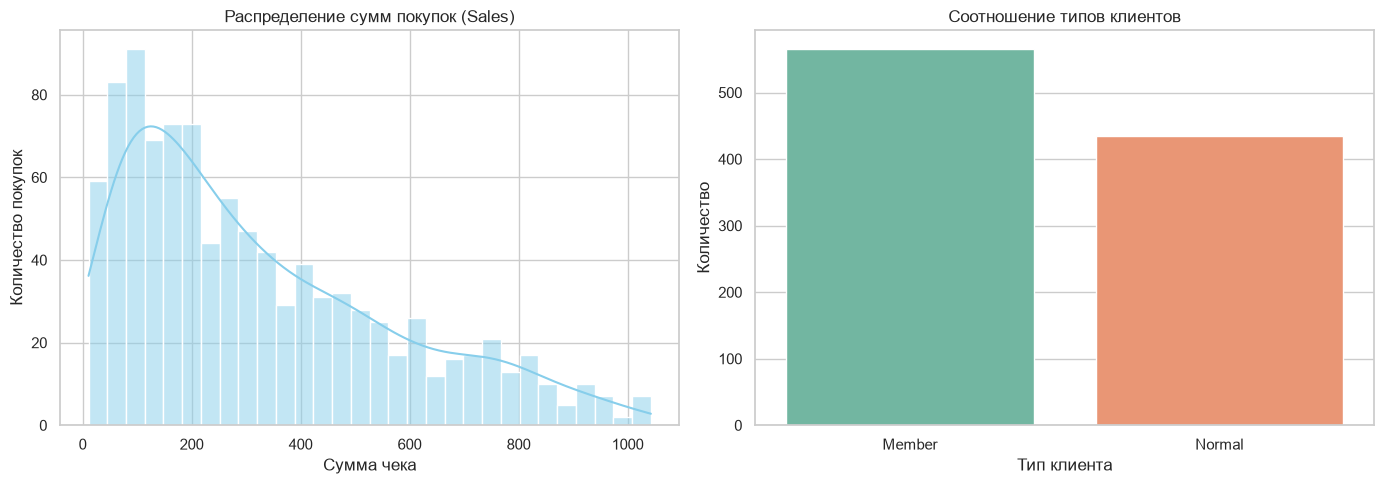

In [6]:
# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")

# Создаем полотно для двух графиков рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Распределение числового признака (сумма продаж - Sales)
sns.histplot(df['Sales'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение сумм покупок (Sales)')
axes[0].set_xlabel('Сумма чека')
axes[0].set_ylabel('Количество покупок')

# График 2: Соотношение категорий (тип клиента - Customer type)
sns.countplot(data=df, x='Customer type', palette='Set2', ax=axes[1])
axes[1].set_title('Соотношение типов клиентов')
axes[1].set_xlabel('Тип клиента')
axes[1].set_ylabel('Количество')

plt.tight_layout()
plt.show()

### Содержательные наблюдения по датасету:

1. **Идеальная заполненность данных:** В таблице ровно 1000 строк и 17 колонок, при этом полностью отсутствуют пропущенные значения (0 null-значений во всех столбцах). Это позволяет сразу переходить к анализу без этапа очистки пропусков.
2. **Особенности форматов данных:** Признаки `Date` (дата покупки) и `Time` (время покупки) распознались как строковый тип `object`. Для полноценного анализа трендов во времени их необходимо будет преобразовать в формат `datetime`. 
3. **Аномалия маржинальности:** Столбец `gross margin percentage` (процент валовой маржи) имеет одинаковое значение (около 4.76%) абсолютно для всех 1000 записей (стандартное отклонение равно 0). Этот столбец не несет никакой полезной информации для поиска закономерностей и может быть удален.